## Linear Regression in Python with Pytorch
### Version 1

### Given
1. Training data (X,Y), where X ∈ Rn×m and Y ∈ Rn
### Objective
1. To find out the weights W ∈ Rm 


**(1) Loss function**

The Mean Squared Error (MSE) loss function is defined as:

$$
L(\mathbf{w}) = \frac{1}{n}\sum_{i=1}^{n}(X_i \cdot \mathbf{w} - Y_i)^2
$$

In matrix notation:

$$
L(\mathbf{w}) = \frac{1}{n}\|X\mathbf{w} - Y\|^2
$$

**(2) Gradient of the loss function**

The gradient of the loss with respect to the weights $\mathbf{w}$ is:

$$
\nabla_{\mathbf{w}} L = \frac{2}{n}X^T(X\mathbf{w} - Y)
$$

**(3) Gradient Descent Update Rule**

Gradient descent updates the weights iteratively using:

$$
\mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \eta \nabla_{\mathbf{w}} L
$$

where:

- $\eta$ is the learning rate.
- $\nabla_{\mathbf{w}} L$ is the gradient of the loss function.
- $\mathbf{w}^{(t)}$ represents the weights at iteration $t$.
- $\mathbf{w}^{(t+1)}$ represents the updated weights.




In [2]:
#Implementation in numpy
import numpy as np
import torch.nn as nn
import torch

In [3]:
def compute_loss(X, Y, w):
    predictions = X @ w
    errors = predictions - Y
    loss = np.mean(errors ** 2)
    return loss

In [4]:
def compute_gradient(X, Y, w):
    n = len(Y)
    predictions = X @ w
    errors = predictions - Y

    gradient = (2/n) * (X.T @ errors)

    return gradient

In [5]:
def update_weights(w, gradient, learning_rate):
    w = w - learning_rate * gradient
    return w

In [6]:
def gradient_descent(X, Y, w, learning_rate, n_iterations):

    for i in range(n_iterations):
        gradient = compute_gradient(X, Y, w)
        w = update_weights(w, gradient, learning_rate)

    return w

In [7]:
def generate_data(n_samples=100):

    # Generate 3 random features
    X = np.random.rand(n_samples, 3)

    # Generate random noise
    noise = np.random.randn(n_samples, 1) * 0.5

    # Generate target values
    y = 2 + 3*X[:, 0:1] + 4*X[:, 1:2] + 5*X[:, 2:3] + noise

    return X, y


In [8]:
X, y = generate_data(n_samples=100)

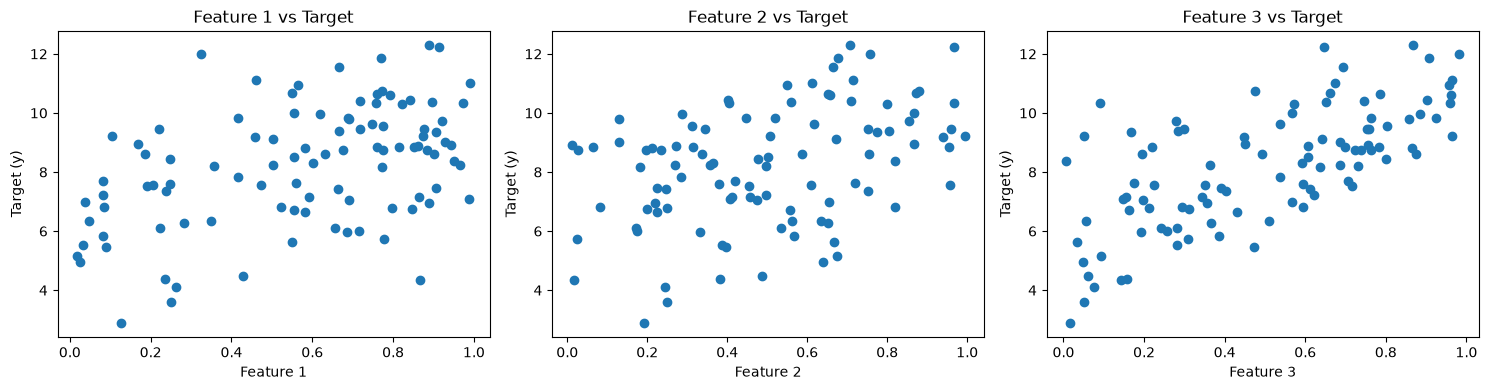

In [9]:
import matplotlib.pyplot as plt



fig, axes = plt.subplots(1, 3, figsize=(15, 4))

feature_names = ['Feature 1', 'Feature 2', 'Feature 3']

for i in range(3):
    axes[i].scatter(X[:, i], y)
    axes[i].set_xlabel(feature_names[i])
    axes[i].set_ylabel('Target (y)')
    axes[i].set_title(f'{feature_names[i]} vs Target')

plt.tight_layout()
plt.show()

In [10]:
print("Number of features :",X.shape[1])

Number of features : 3


In [11]:
w = np.zeros((X.shape[1],1))

In [12]:
ans=gradient_descent(X, y, w, 0.1,5)
ans

array([[3.45132505],
       [3.03346825],
       [3.1598032 ]])

In [13]:
predictions = X @ w
print("X shape:", X.shape)
print("y shape:", y.shape)
print("w shape:", w.shape)  
print("prediction shape:", predictions.shape)  

X shape: (100, 3)
y shape: (100, 1)
w shape: (3, 1)
prediction shape: (100, 1)


In [14]:
#Describtion of the X ie Input Vector
print(type(X))
print(X.shape)  # Number of rows and columns
print(X.ndim)   # Number of dimensions the numpy array
print(X.dtype)  # Data type of elements

<class 'numpy.ndarray'>
(100, 3)
2
float64


In [15]:
print(X[:3])#first three observation

[[0.86361815 0.41203624 0.15461502]
 [0.87314986 0.99326056 0.05063013]
 [0.41575488 0.28441514 0.53617723]]


In [16]:
print(X[:3, :2])#first three observation and first two columns

[[0.86361815 0.41203624]
 [0.87314986 0.99326056]
 [0.41575488 0.28441514]]


## Shifting from Numpy to Pytorch
### Version 2

You can already perform many mathematical operations using NumPy:

- Matrix multiplication
- Addition and subtraction
- Statistical calculations
- Linear algebra
- Implementing linear regression
- Implementing gradient descent

For example, you can implement linear regression using NumPy:

In [17]:
X_t = np.array([[1, 2],
              [2, 3],
              [3, 4]])

w_t = np.array([[2],
              [3]])

y_pred_t = X_t @ w_t

print(y_pred_t)

# NumPy handles the mathematical calculations very efficiently.

[[ 8]
 [13]
 [18]]


## 5. When should you use NumPy and when should you use PyTorch?

| Task | NumPy | PyTorch |
|---|---|---|
| Basic mathematical operations | Excellent | Yes |
| Matrix multiplication | Yes | Yes |
| Data analysis | Excellent | Possible |
| Linear regression from scratch | Yes | Yes |
| Automatic differentiation | No (built-in) | Yes |
| GPU acceleration | Limited / external tools | Yes |
| Deep learning | Manual implementation | Excellent |
| Neural networks | Manual implementation | Built-in tools |

In [18]:
#Conversion of numpy array into the pytorch tensors
a=np.array([[1,2],#numpy array 2*2 matrix
           [3,4]])
print(type(a))
#into tensor
a_tensor=torch.from_numpy(a)
print("Tensor form numpy",a_tensor)
print("Numpy array",a)

<class 'numpy.ndarray'>
Tensor form numpy tensor([[1, 2],
        [3, 4]])
Numpy array [[1 2]
 [3 4]]


In [19]:
X_tensor=torch.from_numpy(X)
print(type(X_tensor))

y_tensor=torch.from_numpy(y)
print(type(y_tensor))

<class 'torch.Tensor'>
<class 'torch.Tensor'>


In [20]:
X_tensor[:3]

tensor([[0.8636, 0.4120, 0.1546],
        [0.8731, 0.9933, 0.0506],
        [0.4158, 0.2844, 0.5362]], dtype=torch.float64)

In [21]:
# Initialize weights with zeros
w = torch.zeros((X_tensor.shape[1], 1), requires_grad=True)

print(w)
print(w.dtype)
X_tensor.dtype

tensor([[0.],
        [0.],
        [0.]], requires_grad=True)
torch.float32


torch.float64

In [22]:
X_tensor = X_tensor.float()
w = w.float()
predictions = X_tensor @ w
predictions.shape  # (100, 1)

torch.Size([100, 1])

In [23]:
loss = torch.mean((predictions - y_tensor) ** 2)

loss.backward()

print(w.grad)

tensor([[-9.9457],
        [-8.6283],
        [-8.9706]])


In [24]:
# Create a weight
w_hawa= torch.tensor([3.0], requires_grad=True)

# Define a simple function
loss_hawa = w_hawa ** 2

# Calculate gradient
loss_hawa.backward()

print(w_hawa.grad)

w_hawa

tensor([6.])


tensor([3.], requires_grad=True)

In [25]:
#Manually updating the weights
learning_rate = 0.01

with torch.no_grad():
    w -= learning_rate * w.grad

In [26]:
w.grad.zero_()#without doing this pytorch accumulate 

tensor([[0.],
        [0.],
        [0.]])

In [27]:
w

tensor([[0.0995],
        [0.0863],
        [0.0897]], requires_grad=True)

### Key Differences from Version 1

- No manual gradient function is needed.
- Use `loss.backward()` instead of computing gradients manually.
- Gradients must be explicitly reset using `w.grad.zero_()` after each weight update.

## PyTorch with Optimizer
### Version 3

### Key Differences from Version 2

- The optimizer handles the weight update logic automatically.
- Use `optimizer.step()` to update weights.
- Use `optimizer.zero_grad()` to reset gradients before the next iteration.
- Use `nn.MSELoss()` to calculate the Mean Squared Error loss.
- Autograd still computes gradients using `loss.backward()`.
- The code is cleaner because we no longer need to update weights manually.

In [28]:
# Define loss function
criterion = nn.MSELoss()

# Create SGD optimizer
optimizer = torch.optim.SGD([w], lr=0.01)

In [29]:


# Training loop
for epoch in range(1000):

    # 1. Forward pass
    predictions = X_tensor @ w

    # 2. Calculate loss
    loss = criterion(predictions, y_tensor)

    # 3. Calculate gradients using autograd
    loss.backward()

    # 4. Update weights using optimizer
    optimizer.step()

    # 5. Reset gradients
    optimizer.zero_grad()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss.item():.6f}")

print("Learned weights:", w)

Epoch 100, Loss: 2.468937
Epoch 200, Loss: 0.578142
Epoch 300, Loss: 0.491888
Epoch 400, Loss: 0.463550
Epoch 500, Loss: 0.443805
Epoch 600, Loss: 0.429426
Epoch 700, Loss: 0.418936
Epoch 800, Loss: 0.411280
Epoch 900, Loss: 0.405693
Epoch 1000, Loss: 0.401613
Learned weights: tensor([[4.5687],
        [5.2462],
        [5.6974]], requires_grad=True)


### Key Differences from Version 2

- The optimizer handles the weight update logic automatically.
- Use `optimizer.step()` to update the weights.
- Use `optimizer.zero_grad()` to reset gradients.
- The code is cleaner because manual weight updates and gradient resetting are no longer needed.

In [31]:
y_tensor.shape

torch.Size([100, 1])

In [32]:
model =nn.Linear(3,1)

In [33]:
X_tensor.shape

torch.Size([100, 3])

In [34]:
predictions = model(X_tensor)

### Version 4: PyTorch Neural Network Module

**Important:** You no longer need to initialize `w` manually or set `requires_grad=True`. The model's parameters already support autograd.

In [35]:

print(model.weight)
print(model.bias)

Parameter containing:
tensor([[-0.4108,  0.4638, -0.5254]], requires_grad=True)
Parameter containing:
tensor([-0.4252], requires_grad=True)


In [36]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

In [37]:


# Create the linear regression model
model = nn.Linear(X_tensor.shape[1], 1)

# Define loss function
criterion = nn.MSELoss()

# Create SGD optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Training loop
n_epochs = 1000

for epoch in range(n_epochs):

    # 1. Forward pass
    y_pred = model(X_tensor)

    # 2. Calculate loss
    loss = criterion(y_pred, y_tensor)

    # 3. Calculate gradients using autograd
    loss.backward()

    # 4. Update weights and bias
    optimizer.step()

    # 5. Reset gradients
    optimizer.zero_grad()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss.item():.6f}")

# Display learned parameters
print("Learned weights:", model.weight)
print("Learned bias:", model.bias)

Epoch 100, Loss: 1.092682
Epoch 200, Loss: 0.909628
Epoch 300, Loss: 0.793686
Epoch 400, Loss: 0.699737
Epoch 500, Loss: 0.623029
Epoch 600, Loss: 0.559956
Epoch 700, Loss: 0.507753
Epoch 800, Loss: 0.464282
Epoch 900, Loss: 0.427881
Epoch 1000, Loss: 0.397247
Learned weights: Parameter containing:
tensor([[2.8059, 3.1654, 4.0494]], requires_grad=True)
Learned bias: Parameter containing:
tensor([3.0448], requires_grad=True)


### Important Notes

- `nn.Linear` includes a bias term by default, so the input `X` should NOT contain an additional bias column.
- Return `model.parameters()` to provide the model's trainable weights and bias to the optimizer.
- This version is closest to how real neural networks are implemented in PyTorch.